In [7]:
import os
import urllib.request
from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm

base_url = "https://physionet.org/files/challenge-2019/1.0.0/training/training_setA/"
output_dir = "./training/training_setA/"
os.makedirs(output_dir, exist_ok=True)

# Generate list of all 20,336 filenames (p000001.psv to p020336.psv)
print("generating file list...")
all_files = [f"p{i:06d}.psv" for i in range(1, 20337)]

def download_one_file(filename):
    save_path = os.path.join(output_dir, filename)
    # Skip if already exists (so you don't redownload the first 500)
    if os.path.exists(save_path) and os.path.getsize(save_path) > 0:
        return
    try:
        urllib.request.urlretrieve(base_url + filename, save_path)
    except Exception:
        pass # Skip errors for now

print(f" Starting Parallel Download of {len(all_files)} files...")

# ThreadPoolExecutor runs 20 downloads at once
with ThreadPoolExecutor(max_workers=20) as executor:
    list(tqdm(executor.map(download_one_file, all_files), total=len(all_files)))

generating file list...
 Starting Parallel Download of 20336 files...


100%|██████████| 20336/20336 [11:13<00:00, 30.18it/s]


Loading 3000 patients for train...
Created 1293 training windows of shape (1293, 48, 5)

📊 Class Distribution:
   Sepsis patients:     270 (679 windows)
   Non-sepsis patients: 2730 (614 windows)
   Imbalance ratio:     0.9:1

✓ Weighted Sampler Created:
   Non-sepsis weight: 1.0529
   Sepsis weight:     0.9521 (0.9x higher)
   Effect: ~50/50 balanced batches during training
Created 1293 training windows of shape (1293, 48, 5)

📊 Class Distribution:
   Sepsis patients:     270 (679 windows)
   Non-sepsis patients: 2730 (614 windows)
   Imbalance ratio:     0.9:1

✓ Weighted Sampler Created:
   Non-sepsis weight: 1.0529
   Sepsis weight:     0.9521 (0.9x higher)
   Effect: ~50/50 balanced batches during training

Starting Training...
📊 Using BALANCED sampling (sepsis patients oversampled)

Starting Training...
📊 Using BALANCED sampling (sepsis patients oversampled)
Epoch 1/30 | Loss: 0.02843
Epoch 1/30 | Loss: 0.02843
Epoch 2/30 | Loss: 0.01770
Epoch 2/30 | Loss: 0.01770
Epoch 3/30 | Lo

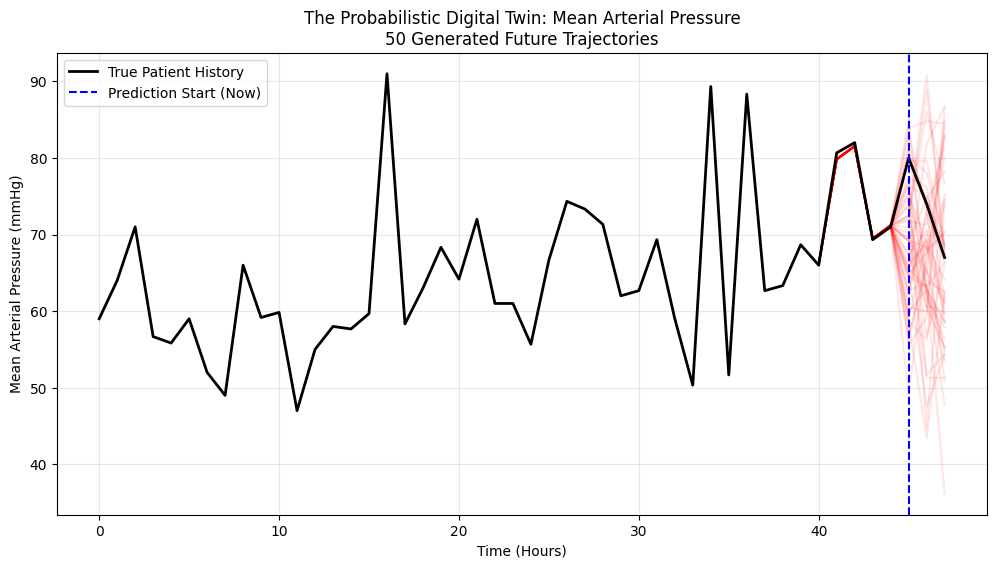


✓ Done! If you see a spread of red lines, that is the uncertainty envelope.
  With balanced sampling, the model now learns BOTH normal AND deterioration patterns.


In [9]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import matplotlib.pyplot as plt
import math
from collections import Counter

# ==========================================
# 0. Configuration
# ==========================================
CONFIG = {
    "DATA_PATH": "./training/training_setA",  # Local folder (or update to your path)
    "VITALS": ['HR', 'MAP', 'O2Sat', 'SBP', 'Resp'],
    "SEQ_LEN": 48,      # Total window size (e.g., 48 hours)
    "PRED_LEN": 3,      # How many hours to predict into the future
    "BATCH_SIZE": 32,
    "HIDDEN_DIM": 128,
    "DIFFUSION_STEPS": 100,
    "EPOCHS": 30,       # Keep low for MVP presentation
    "MAX_FILES": 3000,  # Limit dataset size for speed (MVP mode)
    "USE_BALANCED_SAMPLING": True  # Enable weighted sampling for class balance
}

# Vital sign display info
VITAL_INFO = {
    'HR': {'name': 'Heart Rate', 'unit': 'bpm', 'scale': 100},
    'MAP': {'name': 'Mean Arterial Pressure', 'unit': 'mmHg', 'scale': 100},
    'O2Sat': {'name': 'Oxygen Saturation', 'unit': '%', 'scale': 100},
    'SBP': {'name': 'Systolic Blood Pressure', 'unit': 'mmHg', 'scale': 140},
    'Resp': {'name': 'Respiratory Rate', 'unit': 'breaths/min', 'scale': 20}
}

# ==========================================
# 1. Dataset Loader (With Sepsis Tracking)
# ==========================================
class SepsisDataset(Dataset):
    def __init__(self, data_dir, config, mode='train'):
        self.files = sorted([f for f in os.listdir(data_dir) if f.endswith('.psv')])
        # MVP: Limit to first N files to save time
        self.files = self.files[:config["MAX_FILES"]]
        self.data_dir = data_dir
        self.vitals = config["VITALS"]
        self.seq_len = config["SEQ_LEN"]
        self.data_cache = []
        self.sepsis_flags = []  # Track sepsis status per window

        print(f"Loading {len(self.files)} patients for {mode}...")
        
        sepsis_patients = 0
        non_sepsis_patients = 0

        # Pre-load and process valid windows
        for f in self.files:
            df = pd.read_csv(os.path.join(data_dir, f), sep='|')
            
            # Check if patient developed sepsis
            has_sepsis = df['SepsisLabel'].max() == 1 if 'SepsisLabel' in df.columns else False
            
            if has_sepsis:
                sepsis_patients += 1
            else:
                non_sepsis_patients += 1

            # Select vitals
            df = df[self.vitals]

            # 1. Handle Missing Data (Crucial for Medical Time Series)
            df = df.ffill()
            df = df.bfill()
            df = df.fillna(0)

            # 2. Normalize
            norm_vals = {'HR': 100, 'MAP': 100, 'O2Sat': 100, 'SBP': 140, 'Resp': 20}
            for v in self.vitals:
                df[v] = df[v] / norm_vals[v]

            data = df.values.astype(np.float32)

            # 3. Create Sliding Windows
            if len(data) >= self.seq_len:
                for i in range(0, len(data) - self.seq_len + 1, 12): # Stride of 12
                    window = data[i : i + self.seq_len]
                    self.data_cache.append(window)
                    self.sepsis_flags.append(has_sepsis)

        self.data_cache = np.array(self.data_cache)
        self.sepsis_flags = np.array(self.sepsis_flags)
        
        # Print class distribution
        n_sepsis_windows = self.sepsis_flags.sum()
        n_non_sepsis_windows = len(self.sepsis_flags) - n_sepsis_windows
        
        print(f"Created {len(self.data_cache)} training windows of shape {self.data_cache.shape}")
        print(f"\n📊 Class Distribution:")
        print(f"   Sepsis patients:     {sepsis_patients} ({n_sepsis_windows} windows)")
        print(f"   Non-sepsis patients: {non_sepsis_patients} ({n_non_sepsis_windows} windows)")
        if n_sepsis_windows > 0:
            print(f"   Imbalance ratio:     {n_non_sepsis_windows/n_sepsis_windows:.1f}:1")

    def __len__(self):
        return len(self.data_cache)

    def __getitem__(self, idx):
        # Shape: (Seq_Len, Channels) -> Transpose to (Channels, Seq_Len) for PyTorch Conv1d
        sample = self.data_cache[idx]
        return torch.tensor(sample).transpose(0, 1)


# ==========================================
# 1.5 Weighted Sampler for Balanced Training
# ==========================================
def create_weighted_sampler(dataset):
    """
    Create a weighted sampler that oversamples sepsis patient windows.
    This helps the model learn both normal and deterioration patterns.
    """
    sepsis_flags = dataset.sepsis_flags
    class_counts = Counter(sepsis_flags)
    
    n_samples = len(sepsis_flags)
    n_sepsis = class_counts[True]
    n_non_sepsis = class_counts[False]
    
    # Calculate weights: inverse frequency
    weight_sepsis = n_samples / (2 * n_sepsis) if n_sepsis > 0 else 0
    weight_non_sepsis = n_samples / (2 * n_non_sepsis) if n_non_sepsis > 0 else 0
    
    # Assign weight to each sample
    weights = []
    for is_sepsis in sepsis_flags:
        if is_sepsis:
            weights.append(weight_sepsis)
        else:
            weights.append(weight_non_sepsis)
    
    weights = torch.tensor(weights, dtype=torch.float64)
    
    sampler = WeightedRandomSampler(
        weights=weights,
        num_samples=len(weights),
        replacement=True
    )
    
    print(f"\n✓ Weighted Sampler Created:")
    print(f"   Non-sepsis weight: {weight_non_sepsis:.4f}")
    print(f"   Sepsis weight:     {weight_sepsis:.4f} ({weight_sepsis/weight_non_sepsis:.1f}x higher)")
    print(f"   Effect: ~50/50 balanced batches during training")
    
    return sampler


# ==========================================
# 2. The Diffusion Model (Time-Series Optimized)
# ==========================================
class SinusoidalEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim
    def forward(self, time):
        device = time.device
        half_dim = self.dim // 2
        embeddings = math.log(10000) / (half_dim - 1)
        embeddings = torch.exp(torch.arange(half_dim, device=device) * -embeddings)
        embeddings = time[:, None] * embeddings[None, :]
        embeddings = torch.cat((embeddings.sin(), embeddings.cos()), dim=-1)
        return embeddings

class ResidualBlock(nn.Module):
    def __init__(self, channels, time_emb_dim):
        super().__init__()
        self.conv1 = nn.Conv1d(channels, channels, 3, padding=1)
        self.conv2 = nn.Conv1d(channels, channels, 3, padding=1)
        self.time_mlp = nn.Linear(time_emb_dim, channels)
        self.bn = nn.BatchNorm1d(channels)
        self.act = nn.LeakyReLU(0.2)

    def forward(self, x, t):
        h = self.conv1(self.act(x))
        time_emb = self.time_mlp(self.act(t)).unsqueeze(-1)
        h = h + time_emb
        h = self.conv2(self.act(h))
        return self.bn(h + x)

class MedicalDiffusion(nn.Module):
    def __init__(self, num_channels, seq_len, hidden_dim=64):
        super().__init__()
        self.time_emb = SinusoidalEmbedding(hidden_dim)

        # Input: Channels + Mask (Conditioning)
        self.input_proj = nn.Conv1d(num_channels * 2, hidden_dim, 1)

        self.res1 = ResidualBlock(hidden_dim, hidden_dim)
        self.res2 = ResidualBlock(hidden_dim, hidden_dim)
        self.res3 = ResidualBlock(hidden_dim, hidden_dim)
        self.res4 = ResidualBlock(hidden_dim, hidden_dim)

        self.output_proj = nn.Conv1d(hidden_dim, num_channels, 1)

    def forward(self, x, mask, t):
        # x: Noisy observation
        # mask: 1 for Observed (Past), 0 for Missing (Future)

        # Concatenate Input with Mask so model knows what is "Real" and what is "Hallucination"
        x_in = torch.cat([x, mask], dim=1)

        t_emb = self.time_emb(t)

        h = self.input_proj(x_in)
        h = self.res1(h, t_emb)
        h = self.res2(h, t_emb)
        h = self.res3(h, t_emb)
        h = self.res4(h, t_emb)

        return self.output_proj(h)

# ==========================================
# 3. Training & Inference Logic
# ==========================================
def get_beta_schedule(steps):
    return torch.linspace(0.0001, 0.02, steps)

def train_model():
    dataset = SepsisDataset(CONFIG["DATA_PATH"], CONFIG)
    
    # Use weighted sampling if enabled
    if CONFIG["USE_BALANCED_SAMPLING"]:
        sampler = create_weighted_sampler(dataset)
        dataloader = DataLoader(dataset, batch_size=CONFIG["BATCH_SIZE"], sampler=sampler)
    else:
        dataloader = DataLoader(dataset, batch_size=CONFIG["BATCH_SIZE"], shuffle=True)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = MedicalDiffusion(len(CONFIG["VITALS"]), CONFIG["SEQ_LEN"], CONFIG["HIDDEN_DIM"]).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    betas = get_beta_schedule(CONFIG["DIFFUSION_STEPS"]).to(device)
    alphas = 1. - betas
    alphas_cumprod = torch.cumprod(alphas, dim=0)

    print("\nStarting Training...")
    if CONFIG["USE_BALANCED_SAMPLING"]:
        print("📊 Using BALANCED sampling (sepsis patients oversampled)")
    model.train()

    for epoch in range(CONFIG["EPOCHS"]):
        total_loss = 0
        for batch in dataloader:
            batch = batch.to(device) # Shape: (B, Channels, Time)

            # Create Mask: Hide the last PRED_LEN hours (The "Future")
            mask = torch.ones_like(batch)
            mask[:, :, -CONFIG["PRED_LEN"]:] = 0

            # Add Noise
            noise = torch.randn_like(batch)
            t = torch.randint(0, CONFIG["DIFFUSION_STEPS"], (batch.shape[0],), device=device)

            alpha_bar = alphas_cumprod[t].reshape(-1, 1, 1)
            noisy_input = torch.sqrt(alpha_bar) * batch + torch.sqrt(1 - alpha_bar) * noise

            # IMPUTATION CONDITIONING:
            # The model sees: (Masked Real Data) + (Noisy Future)
            model_input = mask * batch + (1 - mask) * noisy_input

            # Predict
            pred_noise = model(model_input, mask, t)

            # Loss only on the FUTURE (the missing part)
            loss = F.mse_loss(pred_noise * (1-mask), noise * (1-mask))

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        print(f"Epoch {epoch+1}/{CONFIG['EPOCHS']} | Loss: {total_loss/len(dataloader):.5f}")

    return model, dataset

def generate_digital_twin(model, patient_data, device):
    """
    patient_data: (Channels, Time)
    Generates 50 possible futures for this patient.
    """
    model.eval()
    n_samples = 50
    seq_len = patient_data.shape[1]

    # Repeat patient data 50 times
    x = patient_data.unsqueeze(0).repeat(n_samples, 1, 1).to(device)

    # Mask the future
    mask = torch.ones_like(x)
    mask[:, :, -CONFIG["PRED_LEN"]:] = 0

    # Start with pure noise
    curr_img = torch.randn_like(x).to(device)

    betas = get_beta_schedule(CONFIG["DIFFUSION_STEPS"]).to(device)
    alphas = 1. - betas
    alphas_cumprod = torch.cumprod(alphas, dim=0)

    for t in reversed(range(CONFIG["DIFFUSION_STEPS"])):
        # Conditioning: Always reset the PAST to the known ground truth
        curr_img = mask * x + (1 - mask) * curr_img

        t_tensor = torch.full((n_samples,), t, device=device, dtype=torch.long)

        with torch.no_grad():
            pred_noise = model(curr_img, mask, t_tensor)

        alpha = alphas[t]
        alpha_bar = alphas_cumprod[t]
        beta = betas[t]

        if t > 0:
            z = torch.randn_like(curr_img)
        else:
            z = 0

        # DDPM update
        curr_img = (1 / torch.sqrt(alpha)) * (curr_img - ((1 - alpha) / torch.sqrt(1 - alpha_bar)) * pred_noise) + torch.sqrt(beta) * z

    return curr_img.cpu().numpy()

# ==========================================
# 4. Main Execution & Visualization
# ==========================================
if __name__ == "__main__":
    # Check if data exists
    if not os.path.exists(CONFIG["DATA_PATH"]):
        print("Error: Data path not found. Please run the download script first.")
    else:
        # Train
        model, dataset = train_model()

        # Pick a random patient sample
        idx = np.random.randint(0, len(dataset))
        patient_sample = dataset[idx] # (Channels, Time)

        print(f"\nGenerating Digital Twin Futures for patient {idx}...")
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        futures = generate_digital_twin(model, patient_sample, device) # (50, Channels, Time)

        # Visualizing 'MAP' (Mean Arterial Pressure) - Index 1 in VITALS list
        vital_idx = 1
        vital_key = CONFIG["VITALS"][vital_idx]
        vital_name = VITAL_INFO[vital_key]['name']

        plt.figure(figsize=(12, 6))

        # Plot 50 generated futures
        split_pt = CONFIG["SEQ_LEN"] - CONFIG["PRED_LEN"]

        # Un-normalize for display
        scale_factor = VITAL_INFO[vital_key]['scale']

        # Plot 50 Futures
        for i in range(50):
            plt.plot(range(split_pt-5, CONFIG["SEQ_LEN"]),
                     futures[i, vital_idx, split_pt-5:] * scale_factor,
                     color='red', alpha=0.1)

        # Plot Ground Truth
        truth = patient_sample[vital_idx] * scale_factor
        plt.plot(range(CONFIG["SEQ_LEN"]), truth, color='black', linewidth=2, label="True Patient History")

        # Visuals
        plt.axvline(x=split_pt, color='blue', linestyle='--', label="Prediction Start (Now)")
        plt.title(f"The Probabilistic Digital Twin: {vital_name}\n50 Generated Future Trajectories")
        plt.xlabel("Time (Hours)")
        plt.ylabel(f"{vital_name} ({VITAL_INFO[vital_key]['unit']})")
        plt.legend(loc='upper left')
        plt.grid(True, alpha=0.3)
        plt.show()

        print("\n✓ Done! If you see a spread of red lines, that is the uncertainty envelope.")
        print("  With balanced sampling, the model now learns BOTH normal AND deterioration patterns.")

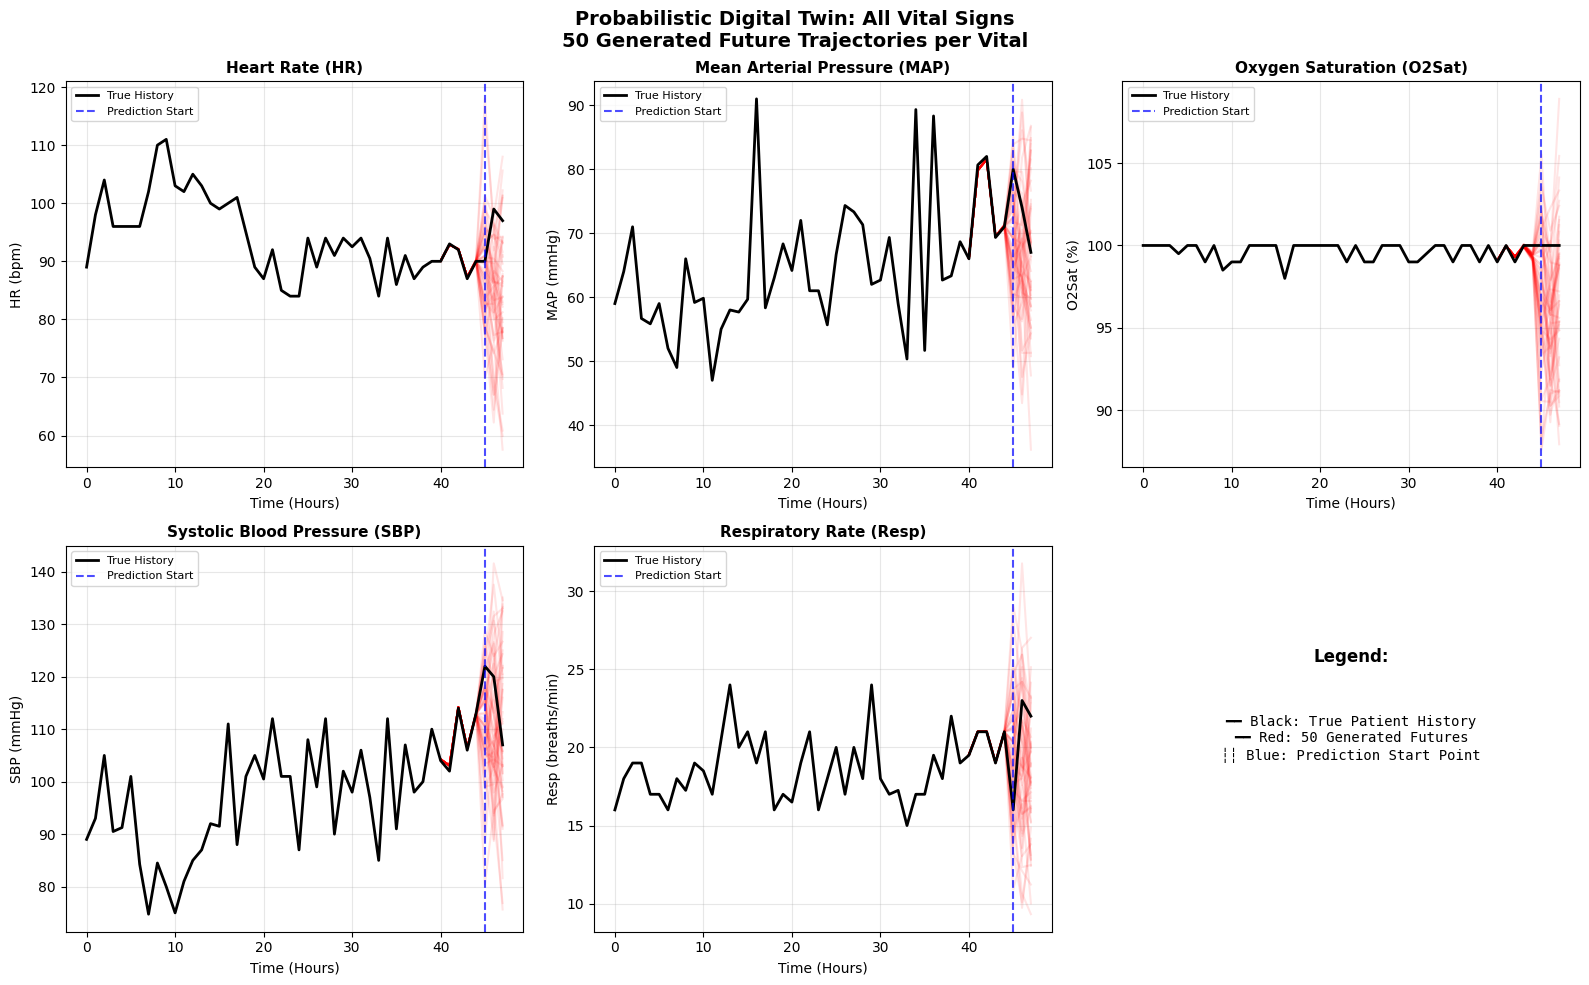


✓ Done! The spread of red lines shows uncertainty in future predictions.
  Wider spread = more uncertainty, Narrow spread = more confident prediction


In [10]:
# ==========================================
# 5. Visualize ALL 5 Vitals (Multi-Plot)
# ==========================================

# Make sure 'model', 'dataset', 'patient_sample', and 'futures' exist from previous cell
# If not, re-run the main cell first

split_pt = CONFIG["SEQ_LEN"] - CONFIG["PRED_LEN"]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for vital_idx, vital_key in enumerate(CONFIG["VITALS"]):
    ax = axes[vital_idx]
    info = VITAL_INFO[vital_key]
    scale_factor = info['scale']
    
    # Plot 50 generated futures (red, semi-transparent)
    for i in range(50):
        ax.plot(range(split_pt-5, CONFIG["SEQ_LEN"]),
                futures[i, vital_idx, split_pt-5:] * scale_factor,
                color='red', alpha=0.1)
    
    # Plot Ground Truth (black line)
    truth = patient_sample[vital_idx].numpy() * scale_factor
    ax.plot(range(CONFIG["SEQ_LEN"]), truth, color='black', linewidth=2, label="True History")
    
    # Prediction start line
    ax.axvline(x=split_pt, color='blue', linestyle='--', alpha=0.7, label="Prediction Start")
    
    # Labels
    ax.set_title(f"{info['name']} ({vital_key})", fontsize=11, fontweight='bold')
    ax.set_xlabel("Time (Hours)")
    ax.set_ylabel(f"{vital_key} ({info['unit']})")
    ax.legend(loc='upper left', fontsize=8)
    ax.grid(True, alpha=0.3)

# Hide the 6th subplot (we have 5 vitals)
axes[5].axis('off')

# Add legend explanation in empty subplot
axes[5].text(0.5, 0.7, "Legend:", fontsize=12, fontweight='bold', 
             ha='center', transform=axes[5].transAxes)
axes[5].text(0.5, 0.5, "━━ Black: True Patient History\n"
                       "━━ Red: 50 Generated Futures\n"
                       "┆┆ Blue: Prediction Start Point",
             fontsize=10, ha='center', va='center', transform=axes[5].transAxes,
             family='monospace')

plt.suptitle("Probabilistic Digital Twin: All Vital Signs\n"
             "50 Generated Future Trajectories per Vital", 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n✓ Done! The spread of red lines shows uncertainty in future predictions.")
print("  Wider spread = more uncertainty, Narrow spread = more confident prediction")

In [11]:
# ==========================================
# 6. Quantitative Evaluation Metrics
# ==========================================

def evaluate_diffusion(model, dataset, device, n_eval=100):
    """
    Compute quantitative metrics for probabilistic forecasts.
    
    Metrics:
    - MAE: Mean Absolute Error of mean prediction
    - Coverage: % of ground truth within 90% prediction interval
    - CRPS-like: Continuous Ranked Probability Score approximation
    """
    model.eval()
    
    all_maes = []
    all_coverages = []
    all_interval_widths = []
    vital_maes = {v: [] for v in CONFIG["VITALS"]}
    vital_coverages = {v: [] for v in CONFIG["VITALS"]}
    
    indices = np.random.choice(len(dataset), min(n_eval, len(dataset)), replace=False)
    
    print(f"\n🔬 Evaluating on {len(indices)} samples...")
    
    for i, idx in enumerate(indices):
        if (i + 1) % 20 == 0:
            print(f"   Processing sample {i+1}/{len(indices)}...")
        
        patient_sample = dataset[idx]
        futures = generate_digital_twin(model, patient_sample, device)  # (50, C, T)
        
        # Ground truth for the prediction window
        truth = patient_sample[:, -CONFIG["PRED_LEN"]:].numpy()  # (C, pred_len)
        preds = futures[:, :, -CONFIG["PRED_LEN"]:]  # (50, C, pred_len)
        
        # Mean prediction
        mean_pred = preds.mean(axis=0)  # (C, pred_len)
        
        # MAE
        mae = np.abs(mean_pred - truth).mean()
        all_maes.append(mae)
        
        # Per-vital MAE
        for v_idx, v_name in enumerate(CONFIG["VITALS"]):
            v_mae = np.abs(mean_pred[v_idx] - truth[v_idx]).mean()
            vital_maes[v_name].append(v_mae * VITAL_INFO[v_name]['scale'])
        
        # 90% Prediction Interval Coverage
        lower = np.percentile(preds, 5, axis=0)
        upper = np.percentile(preds, 95, axis=0)
        covered = ((truth >= lower) & (truth <= upper)).mean()
        all_coverages.append(covered)
        
        # Per-vital coverage
        for v_idx, v_name in enumerate(CONFIG["VITALS"]):
            v_covered = ((truth[v_idx] >= lower[v_idx]) & (truth[v_idx] <= upper[v_idx])).mean()
            vital_coverages[v_name].append(v_covered)
        
        # Interval width (uncertainty measure)
        interval_width = (upper - lower).mean()
        all_interval_widths.append(interval_width)
    
    # Print results
    print("\n" + "="*60)
    print("📊 DIFFUSION MODEL EVALUATION RESULTS")
    print("="*60)
    
    print(f"\n🎯 Overall Metrics:")
    print(f"   Mean Absolute Error (normalized): {np.mean(all_maes):.4f}")
    print(f"   90% Prediction Interval Coverage: {np.mean(all_coverages)*100:.1f}%")
    print(f"   Average Interval Width:           {np.mean(all_interval_widths):.4f}")
    
    print(f"\n📈 Per-Vital MAE (in original units):")
    for v_name in CONFIG["VITALS"]:
        unit = VITAL_INFO[v_name]['unit']
        print(f"   {v_name:6s}: {np.mean(vital_maes[v_name]):6.2f} {unit}")
    
    print(f"\n📊 Per-Vital Coverage (target: 90%):")
    for v_name in CONFIG["VITALS"]:
        cov = np.mean(vital_coverages[v_name]) * 100
        status = "✓" if 80 <= cov <= 95 else "⚠️"
        print(f"   {v_name:6s}: {cov:5.1f}% {status}")
    
    # Calibration interpretation
    avg_coverage = np.mean(all_coverages)
    print(f"\n🔍 Calibration Analysis:")
    if avg_coverage > 0.95:
        print("   → Model is UNDERCONFIDENT (intervals too wide)")
        print("   → Consider: reducing noise, more training epochs")
    elif avg_coverage < 0.80:
        print("   → Model is OVERCONFIDENT (intervals too narrow)")
        print("   → Consider: increasing model capacity, more diffusion steps")
    else:
        print("   → Calibration looks GOOD! ✅")
    
    return {
        'mae': np.mean(all_maes),
        'coverage': np.mean(all_coverages),
        'interval_width': np.mean(all_interval_widths),
        'vital_maes': {k: np.mean(v) for k, v in vital_maes.items()},
        'vital_coverages': {k: np.mean(v) for k, v in vital_coverages.items()}
    }

# Run evaluation
print("\n" + "="*60)
print("RUNNING QUANTITATIVE EVALUATION")
print("="*60)
metrics = evaluate_diffusion(model, dataset, device, n_eval=50)


RUNNING QUANTITATIVE EVALUATION

🔬 Evaluating on 50 samples...
   Processing sample 20/50...
   Processing sample 40/50...

📊 DIFFUSION MODEL EVALUATION RESULTS

🎯 Overall Metrics:
   Mean Absolute Error (normalized): 0.0795
   90% Prediction Interval Coverage: 89.2%
   Average Interval Width:           0.3516

📈 Per-Vital MAE (in original units):
   HR    :   6.06 bpm
   MAP   :   9.14 mmHg
   O2Sat :   2.15 %
   SBP   :  11.35 mmHg
   Resp  :   2.86 breaths/min

📊 Per-Vital Coverage (target: 90%):
   HR    :  90.7% ✓
   MAP   :  83.3% ✓
   O2Sat :  98.7% ⚠️
   SBP   :  84.7% ✓
   Resp  :  88.7% ✓

🔍 Calibration Analysis:
   → Calibration looks GOOD! ✅



📊 Generating enhanced visualization with confidence intervals...


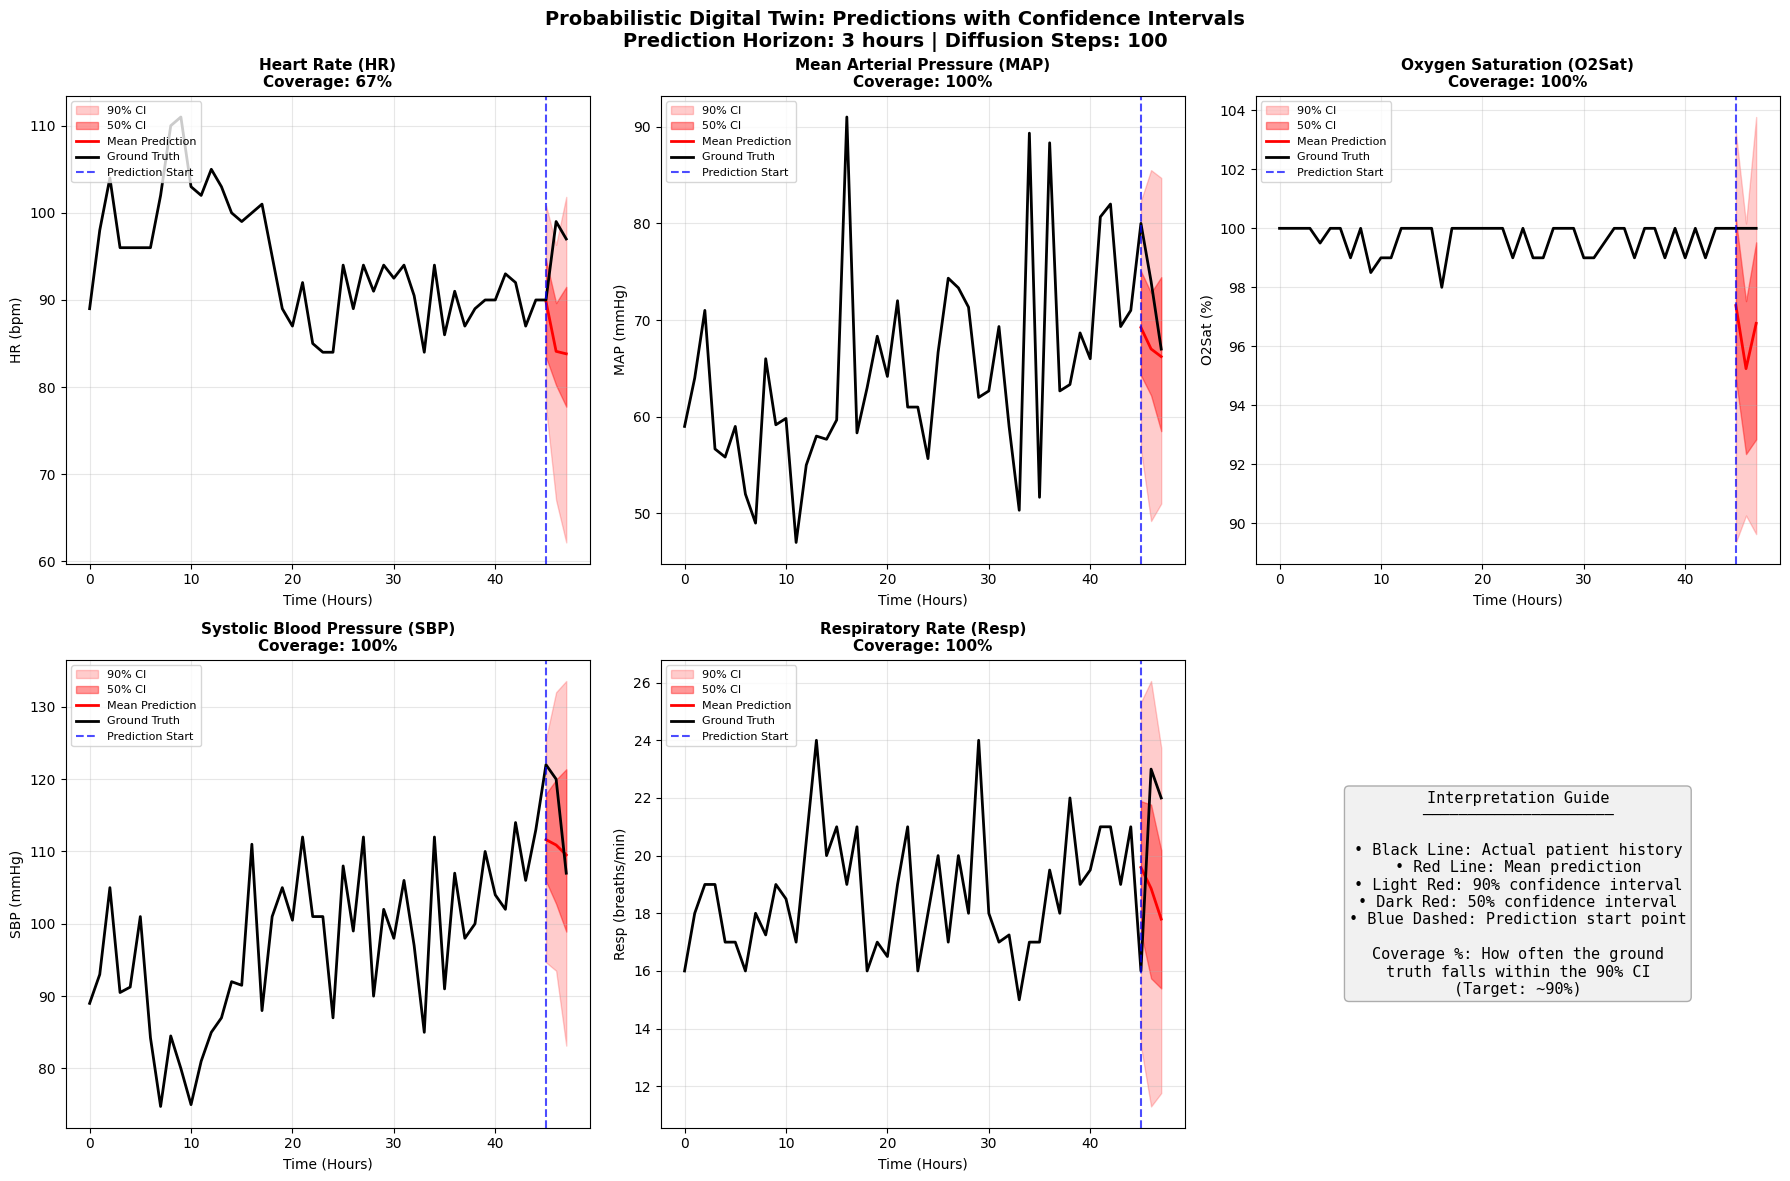

In [12]:
# ==========================================
# 7. Visualization with Confidence Intervals
# ==========================================

def plot_with_confidence_intervals(patient_sample, futures, save_fig=False):
    """
    Enhanced visualization showing mean prediction with confidence intervals.
    """
    split_pt = CONFIG["SEQ_LEN"] - CONFIG["PRED_LEN"]
    
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    axes = axes.flatten()
    
    for vital_idx, vital_key in enumerate(CONFIG["VITALS"]):
        ax = axes[vital_idx]
        info = VITAL_INFO[vital_key]
        scale_factor = info['scale']
        
        # Get predictions for this vital
        preds = futures[:, vital_idx, :] * scale_factor  # (50, T)
        truth = patient_sample[vital_idx].numpy() * scale_factor
        
        # Calculate statistics
        pred_mean = preds.mean(axis=0)
        pred_std = preds.std(axis=0)
        pred_5 = np.percentile(preds, 5, axis=0)
        pred_25 = np.percentile(preds, 25, axis=0)
        pred_75 = np.percentile(preds, 75, axis=0)
        pred_95 = np.percentile(preds, 95, axis=0)
        
        time_range = np.arange(CONFIG["SEQ_LEN"])
        
        # Plot 90% CI (lighter)
        ax.fill_between(time_range[split_pt:], 
                        pred_5[split_pt:], pred_95[split_pt:],
                        alpha=0.2, color='red', label='90% CI')
        
        # Plot 50% CI (darker)
        ax.fill_between(time_range[split_pt:], 
                        pred_25[split_pt:], pred_75[split_pt:],
                        alpha=0.4, color='red', label='50% CI')
        
        # Plot mean prediction
        ax.plot(time_range[split_pt:], pred_mean[split_pt:], 
                color='red', linewidth=2, label='Mean Prediction')
        
        # Plot Ground Truth
        ax.plot(time_range, truth, color='black', linewidth=2, label='Ground Truth')
        
        # Prediction start line
        ax.axvline(x=split_pt, color='blue', linestyle='--', alpha=0.7, label='Prediction Start')
        
        # Check if ground truth is within 90% CI
        future_truth = truth[split_pt:]
        future_5 = pred_5[split_pt:]
        future_95 = pred_95[split_pt:]
        coverage = ((future_truth >= future_5) & (future_truth <= future_95)).mean() * 100
        
        # Labels
        ax.set_title(f"{info['name']} ({vital_key})\nCoverage: {coverage:.0f}%", 
                     fontsize=11, fontweight='bold')
        ax.set_xlabel("Time (Hours)")
        ax.set_ylabel(f"{vital_key} ({info['unit']})")
        ax.legend(loc='upper left', fontsize=8)
        ax.grid(True, alpha=0.3)
    
    # Info panel in 6th subplot
    axes[5].axis('off')
    info_text = (
        "Interpretation Guide\n"
        "─────────────────────\n\n"
        "• Black Line: Actual patient history\n"
        "• Red Line: Mean prediction\n"
        "• Light Red: 90% confidence interval\n"
        "• Dark Red: 50% confidence interval\n"
        "• Blue Dashed: Prediction start point\n\n"
        "Coverage %: How often the ground\n"
        "truth falls within the 90% CI\n"
        "(Target: ~90%)"
    )
    axes[5].text(0.5, 0.5, info_text, fontsize=11, ha='center', va='center',
                 transform=axes[5].transAxes, family='monospace',
                 bbox=dict(boxstyle='round', facecolor='lightgray', alpha=0.3))
    
    plt.suptitle("Probabilistic Digital Twin: Predictions with Confidence Intervals\n"
                 f"Prediction Horizon: {CONFIG['PRED_LEN']} hours | Diffusion Steps: {CONFIG['DIFFUSION_STEPS']}", 
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    
    if save_fig:
        plt.savefig('digital_twin_predictions.png', dpi=150, bbox_inches='tight')
        print("📊 Figure saved as 'digital_twin_predictions.png'")
    
    plt.show()

# Generate new visualization with confidence intervals
print("\n📊 Generating enhanced visualization with confidence intervals...")
plot_with_confidence_intervals(patient_sample, futures, save_fig=False)


🔬 Comparing Sepsis vs Non-Sepsis Patients
   Available: 679 sepsis, 614 non-sepsis windows


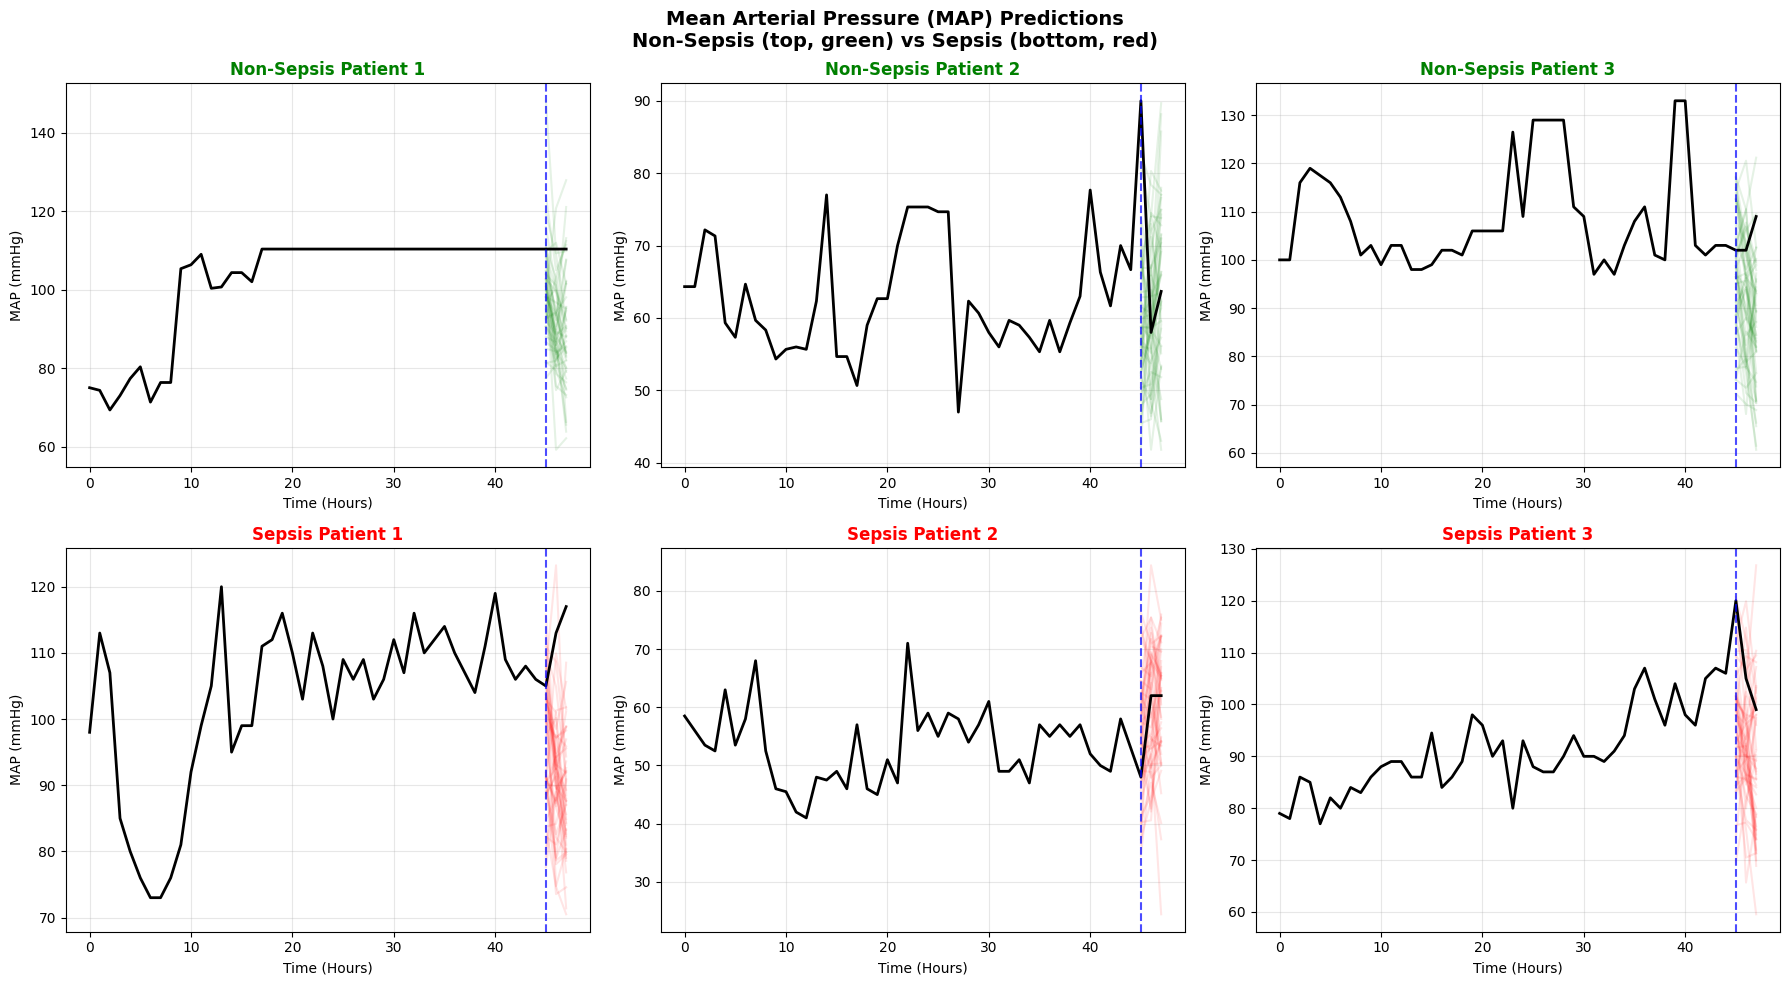


✓ Observation: Sepsis patients often show wider uncertainty and
  more volatile predictions due to physiological instability.


In [13]:
# ==========================================
# 8. Compare Multiple Patients (Sepsis vs Non-Sepsis)
# ==========================================

def compare_sepsis_vs_nonsepsis(model, dataset, device, n_samples=3):
    """
    Compare predictions for sepsis vs non-sepsis patients.
    """
    # Find sepsis and non-sepsis indices
    sepsis_indices = np.where(dataset.sepsis_flags == True)[0]
    nonsepsis_indices = np.where(dataset.sepsis_flags == False)[0]
    
    print(f"\n🔬 Comparing Sepsis vs Non-Sepsis Patients")
    print(f"   Available: {len(sepsis_indices)} sepsis, {len(nonsepsis_indices)} non-sepsis windows")
    
    # Sample from each group
    sepsis_samples = np.random.choice(sepsis_indices, min(n_samples, len(sepsis_indices)), replace=False)
    nonsepsis_samples = np.random.choice(nonsepsis_indices, min(n_samples, len(nonsepsis_indices)), replace=False)
    
    fig, axes = plt.subplots(2, n_samples, figsize=(6*n_samples, 10))
    
    vital_idx = 1  # MAP - often most indicative of sepsis
    vital_key = CONFIG["VITALS"][vital_idx]
    scale_factor = VITAL_INFO[vital_key]['scale']
    split_pt = CONFIG["SEQ_LEN"] - CONFIG["PRED_LEN"]
    
    # Plot non-sepsis patients
    for i, idx in enumerate(nonsepsis_samples):
        ax = axes[0, i]
        patient_sample = dataset[idx]
        futures = generate_digital_twin(model, patient_sample, device)
        
        preds = futures[:, vital_idx, :] * scale_factor
        truth = patient_sample[vital_idx].numpy() * scale_factor
        
        # Plot trajectories
        for j in range(50):
            ax.plot(range(split_pt, CONFIG["SEQ_LEN"]), 
                    preds[j, split_pt:], color='green', alpha=0.1)
        ax.plot(range(CONFIG["SEQ_LEN"]), truth, color='black', linewidth=2)
        ax.axvline(x=split_pt, color='blue', linestyle='--', alpha=0.7)
        
        ax.set_title(f"Non-Sepsis Patient {i+1}", fontweight='bold', color='green')
        ax.set_xlabel("Time (Hours)")
        ax.set_ylabel(f"MAP (mmHg)")
        ax.grid(True, alpha=0.3)
    
    # Plot sepsis patients
    for i, idx in enumerate(sepsis_samples):
        ax = axes[1, i]
        patient_sample = dataset[idx]
        futures = generate_digital_twin(model, patient_sample, device)
        
        preds = futures[:, vital_idx, :] * scale_factor
        truth = patient_sample[vital_idx].numpy() * scale_factor
        
        # Plot trajectories
        for j in range(50):
            ax.plot(range(split_pt, CONFIG["SEQ_LEN"]), 
                    preds[j, split_pt:], color='red', alpha=0.1)
        ax.plot(range(CONFIG["SEQ_LEN"]), truth, color='black', linewidth=2)
        ax.axvline(x=split_pt, color='blue', linestyle='--', alpha=0.7)
        
        ax.set_title(f"Sepsis Patient {i+1}", fontweight='bold', color='red')
        ax.set_xlabel("Time (Hours)")
        ax.set_ylabel(f"MAP (mmHg)")
        ax.grid(True, alpha=0.3)
    
    plt.suptitle(f"Mean Arterial Pressure (MAP) Predictions\nNon-Sepsis (top, green) vs Sepsis (bottom, red)", 
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    print("\n✓ Observation: Sepsis patients often show wider uncertainty and")
    print("  more volatile predictions due to physiological instability.")

# Run comparison
compare_sepsis_vs_nonsepsis(model, dataset, device, n_samples=3)